# Terminal-hub predictability over time

For each group size, this notebook randomly selects 100 parameter vectors tied at the highest mean terminal efficiency and reruns one independently seeded episode per vector. At normalized time $t$, let $H(t)$ be the set of nodes tied for maximum total degree and let $h^*$ be the unique terminal hub. The tie-aware prediction score is

$$A(t) = \frac{\mathbf{1}[h^* \in H(t)]}{|H(t)|}.$$

The plotted curve averages this score over the selected vectors. Trajectories without a unique terminal hub are reported and excluded from the accuracy curve.

## Configuration

In [1]:
SOURCE_RUN = "artifacts/simulation_runs/run-20260809T034029.zarr"
SOURCE_ENDPOINT_CSV = (
    "artifacts/simulation_runs/"
    "run-20260809T034029_mean_welfare_last_step.csv"
)
N_VECTORS_PER_SIZE = 100
SELECTION_SEED = 20260827
RERUN_SEED = 20260828
BAYESIAN_BOOTSTRAP_DRAWS = 20_000
BAYESIAN_BOOTSTRAP_SEED = 20260829
CREDIBLE_MASS = 0.95
FORCE_RERUN = False

In [2]:
from itertools import permutations
import os
from pathlib import Path
import sys

os.environ.setdefault("JAX_PLATFORMS", "cpu")

PROJECT_ROOT = next(
    parent
    for parent in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (parent / "pyproject.toml").is_file() and (parent / "tasks").is_dir()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import jax.numpy as jnp
import pandas as pd
import scienceplots  # noqa: F401 - registers plotting styles
from IPython.display import display
from jax import config as jax_config, random
from matplotlib.patches import Patch
from matplotlib_inline.backend_inline import set_matplotlib_formats
import numpyro.distributions as dist
from numpyro.diagnostics import hpdi
from tqdm.auto import tqdm

from network_creation.core.model import ActorScheduler
from network_creation.core.observability import (
    EpisodeEndEvent,
    EpisodeStartEvent,
    ObservationSampling,
    StepEvent,
)
from network_creation.io import read_json
from network_creation.stats.topology_welfare import (
    centered_mean_welfare,
    reference_centered_mean_welfare,
)
from tasks.policies.policy_run import _build_policy_simulation_runtime

jax_config.update("jax_enable_x64", True)

SOURCE_RUN_PATH = (PROJECT_ROOT / SOURCE_RUN).resolve()
SOURCE_ENDPOINT_PATH = (PROJECT_ROOT / SOURCE_ENDPOINT_CSV).resolve()
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "hub_predictability"
FIGURE_DIR = PROJECT_ROOT / "artifacts" / "figures" / SOURCE_RUN_PATH.stem
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
artifact_stem = (
    f"terminal_hub_predictability_top{N_VECTORS_PER_SIZE}"
    f"_selection{SELECTION_SEED}_rerun{RERUN_SEED}_v1"
)
SELECTED_VECTORS_PATH = ARTIFACT_DIR / f"{artifact_stem}_vectors.csv"
RESULTS_PATH = ARTIFACT_DIR / f"{artifact_stem}_results.csv"
FIGURE_PATH = FIGURE_DIR / "terminal_hub_predictability_over_time.pdf"
HYPOTHESIS_FIGURE_PATH = (
    FIGURE_DIR / "terminal_hub_predictability_bayesian_hypotheses.pdf"
)

plt.style.use(["science", "no-latex"])
set_matplotlib_formats("svg")
plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 14,
    "legend.fontsize": 11,
})

## Select maximum-efficiency vectors

In [3]:
def select_top_vectors_with_random_ties(frame, n_vectors, rng):
    """Select exactly n_vectors, sampling uniformly at the cutoff tie."""
    values = frame["source_terminal_efficiency"].to_numpy()
    cutoff = np.partition(values, -n_vectors)[-n_vectors]
    above = frame.loc[values > cutoff]
    tied = frame.loc[values == cutoff]
    needed = n_vectors - len(above)
    if needed < 0 or needed > len(tied):
        raise RuntimeError("invalid top-vector tie partition")
    tied_positions = rng.choice(len(tied), size=needed, replace=False)
    return pd.concat((above, tied.iloc[tied_positions]), ignore_index=True), cutoff

endpoint = pd.read_csv(SOURCE_ENDPOINT_PATH).rename(columns={
    "centered_mean_welfare.mean": "source_terminal_efficiency"
})
endpoint.insert(0, "input_index", np.arange(len(endpoint), dtype=np.int64))
if len(endpoint) != 98_304:
    raise ValueError(f"Expected 98,304 source inputs, found {len(endpoint):,}")

selection_rng = np.random.default_rng(SELECTION_SEED)
selected_parts = []
selection_rows = []
for n_agents, size_frame in endpoint.groupby("n_agents", sort=True):
    selected_size, cutoff = select_top_vectors_with_random_ties(
        size_frame.reset_index(drop=True),
        N_VECTORS_PER_SIZE,
        selection_rng,
    )
    selected_parts.append(selected_size)
    selection_rows.append({
        "n_agents": int(n_agents),
        "selected_vectors": len(selected_size),
        "selection_cutoff": float(cutoff),
        "vectors_at_cutoff": int(
            np.count_nonzero(size_frame["source_terminal_efficiency"] == cutoff)
        ),
    })

selected = (
    pd.concat(selected_parts, ignore_index=True)
    .sort_values(["n_agents", "input_index"])
    .reset_index(drop=True)
)
seed_sequences = np.random.SeedSequence(RERUN_SEED).spawn(len(selected))
selected["rerun_seed"] = [
    int(sequence.generate_state(1, dtype=np.uint64)[0])
    for sequence in seed_sequences
]
selected["vector_index"] = selected.groupby("n_agents").cumcount()
selected.to_csv(SELECTED_VECTORS_PATH, index=False)

selection_summary = pd.DataFrame(selection_rows)
display(selection_summary)
display(selected.groupby("n_agents")["visibility_distance"].value_counts().unstack(fill_value=0))

,n_agents,selected_vectors,selection_cutoff,vectors_at_cutoff
0,10,100,1.0,5326
1,50,100,1.0,1493
2,100,100,1.0,264


visibility_distance,3,4,5,6,7
n_agents,,,,,
10,14,25,13,20,28
50,0,0,12,41,47
100,0,0,0,3,97


## Hub observer and simulation

In [4]:
class HubPredictabilityObserver:
    """Record tie-aware current-hub accuracy on a normalized time grid."""

    def __init__(self, n_agents):
        self.n_agents = int(n_agents)
        self.observation_sampling = ObservationSampling.periodic(self.n_agents)
        self.reset()

    def reset(self):
        self._steps = []
        self._hub_masks = []
        self.predictability = None
        self.terminal_hub_id = -1
        self.terminal_unique = False

    def observes_step(self, step_index, max_steps):
        return self.observation_sampling.samples_step(step_index, max_steps)

    def _hub_mask(self, graph):
        degrees = np.asarray(graph.degree(mode="all"), dtype=np.int64)
        return degrees == degrees.max()

    def on_episode_start(self, event: EpisodeStartEvent):
        if event.n_agents != self.n_agents:
            raise ValueError("observer and episode group sizes differ")
        self._steps = [0]
        self._hub_masks = [self._hub_mask(event.initial_state.graph)]

    def on_step_end(self, event: StepEvent):
        self._steps.append(event.step + 1)
        self._hub_masks.append(self._hub_mask(event.post_state.graph))

    def on_episode_end(self, event: EpisodeEndEvent):
        expected_steps = np.arange(0, event.current_step + 1, self.n_agents)
        np.testing.assert_array_equal(self._steps, expected_steps)
        masks = np.asarray(self._hub_masks, dtype=np.bool_)
        terminal_mask = self._hub_mask(event.final_state.graph)
        terminal_ids = np.flatnonzero(terminal_mask)
        self.terminal_unique = terminal_ids.size == 1
        if not self.terminal_unique:
            self.predictability = np.full(len(self._steps), np.nan, dtype=np.float64)
            return
        self.terminal_hub_id = int(terminal_ids[0])
        self.predictability = (
            masks[:, self.terminal_hub_id].astype(np.float64)
            / masks.sum(axis=1)
        )

    def get(self):
        if self.predictability is None:
            raise RuntimeError("observer has not completed an episode")
        return {
            "raw_step": np.asarray(self._steps, dtype=np.int64),
            "predictability": self.predictability.copy(),
            "terminal_hub_id": self.terminal_hub_id,
            "terminal_unique": self.terminal_unique,
        }

run_config = read_json(SOURCE_RUN_PATH / "run_config.json")
runtime, _, _ = _build_policy_simulation_runtime(run_config)
if runtime.sweep.total_inputs != len(endpoint):
    raise ValueError("source endpoint table does not match the reconstructed sweep")

def run_selected_vector(row):
    n_agents = int(row.n_agents)
    observer = HubPredictabilityObserver(n_agents)
    prepared = runtime.prepare_simulation(
        int(row.input_index),
        observers=(observer,),
    )
    if prepared.settings.n_agents != n_agents:
        raise ValueError("selected row resolves to the wrong group size")

    simulator = prepared.simulator
    rerun_seed = int(row.rerun_seed)
    simulator.rng = np.random.default_rng(rerun_seed)
    simulator.actor_scheduler = ActorScheduler(
        seed=rerun_seed,
        n_agents=n_agents,
        n_actors=prepared.settings.n_actors,
        activation_weights=tuple(agent.activation_weight for agent in simulator.agents),
    )
    simulator.run(n_episodes=1, reset_observers=True)
    observation = observer.get()

    benefit = float(row.benefit_to_cost_ratio)
    discount = float(row.distance_discount)
    maximum_welfare = reference_centered_mean_welfare(
        reference="max",
        n_agents=n_agents,
        benefit_to_cost_ratio=benefit,
        distance_discount=discount,
    )
    terminal_efficiency = centered_mean_welfare(
        simulator.env.state.graph,
        benefit_to_cost_ratio=benefit,
        distance_discount=discount,
    ) / (maximum_welfare + 1e-8)

    records = []
    for raw_step, predictability in zip(
        observation["raw_step"],
        observation["predictability"],
        strict=True,
    ):
        records.append({
            "input_index": int(row.input_index),
            "n_agents": n_agents,
            "visibility_distance": int(row.visibility_distance),
            "outside_optimism": float(row.outside_optimism),
            "exploration": float(row.exploration),
            "source_terminal_efficiency": float(row.source_terminal_efficiency),
            "rerun_seed": rerun_seed,
            "normalized_time": float(raw_step / n_agents),
            "predictability": float(predictability),
            "terminal_hub_id": int(observation["terminal_hub_id"]),
            "terminal_unique": bool(observation["terminal_unique"]),
            "rerun_terminal_efficiency": float(terminal_efficiency),
        })
    return records

In [5]:
expected_input_indices = set(selected["input_index"].astype(int))
if RESULTS_PATH.exists() and not FORCE_RERUN:
    results = pd.read_csv(RESULTS_PATH)
    cached_input_indices = set(results["input_index"].astype(int))
    if cached_input_indices != expected_input_indices:
        raise ValueError("cached results do not match the selected vectors")
else:
    records = []
    for row in tqdm(
        selected.itertuples(index=False),
        total=len(selected),
        desc="Hub trajectories",
        unit="vector",
    ):
        records.extend(run_selected_vector(row))
    results = pd.DataFrame.from_records(records)
    results.to_csv(RESULTS_PATH, index=False)

if results["terminal_unique"].dtype != np.bool_:
    results["terminal_unique"] = results["terminal_unique"].map({
        True: True, False: False, "True": True, "False": False
    })

print(f"Selected vectors: {SELECTED_VECTORS_PATH}")
print(f"Cached trajectories: {RESULTS_PATH}")

Selected vectors: /home/hdahmou/Projects/Network_creation/artifacts/hub_predictability/terminal_hub_predictability_top100_selection20260827_rerun20260828_v1_vectors.csv
Cached trajectories: /home/hdahmou/Projects/Network_creation/artifacts/hub_predictability/terminal_hub_predictability_top100_selection20260827_rerun20260828_v1_results.csv


## Validation and posterior mean curves

Shading shows pointwise 95% Bayesian-bootstrap credible intervals for each population mean curve. A single Dirichlet weight is applied to each complete trajectory, preserving dependence across normalized time.

### Longitudinal-data interpretation

This construction is appropriate for repeated measurements because complete trajectories, rather than individual time points, are treated as exchangeable sampling units. It targets the population mean curve and functionals of that curve, such as normalized AUC, under the assumptions that trajectories are independent within each group and observed on a common time grid. It does not assume that measurements within a trajectory are independent. The posterior has a superpopulation interpretation for vector-episode trajectories; it does not include a finite-population correction for selecting vectors without replacement from the observed maximum-efficiency set.

The analysis is not a generative time-series model: it does not estimate an autocorrelation process, forecast future observations, or generate trajectory shapes outside the observed support. The displayed credible intervals are pointwise, not a simultaneous band over the full horizon; the reported curve-dominance probabilities instead compare each complete 61-dimensional posterior draw jointly. Because there is one rerun per parameter vector, uncertainty from variation between vectors and stochastic variation between episodes cannot be separated without repeated episodes per vector.

In [6]:
trajectory_summary = results.drop_duplicates("input_index")
summary_rows = []
for n_agents, size_summary in trajectory_summary.groupby("n_agents", sort=True):
    summary_rows.append({
        "n_agents": int(n_agents),
        "vectors": len(size_summary),
        "unique_terminal_hubs": int(size_summary["terminal_unique"].sum()),
        "rerun_efficiency_ge_0.99": int(
            (size_summary["rerun_terminal_efficiency"] >= 0.99).sum()
        ),
        "mean_rerun_terminal_efficiency": float(
            size_summary["rerun_terminal_efficiency"].mean()
        ),
    })
summary = pd.DataFrame(summary_rows)
display(summary.style.format({"mean_rerun_terminal_efficiency": "{:.4f}"}))

accuracy_matrices = {}
for n_agents in sorted(results["n_agents"].unique()):
    valid_inputs = trajectory_summary.loc[
        (trajectory_summary["n_agents"] == n_agents)
        & trajectory_summary["terminal_unique"],
        "input_index",
    ]
    matrix = (
        results.loc[results["input_index"].isin(valid_inputs)]
        .pivot(index="input_index", columns="normalized_time", values="predictability")
        .sort_index(axis=1)
    )
    if matrix.shape[1] != 61:
        raise ValueError(f"Expected 61 normalized times for n={n_agents}")
    np.testing.assert_allclose(matrix.iloc[:, 0], 1.0 / n_agents)
    np.testing.assert_allclose(matrix.iloc[:, -1], 1.0)
    accuracy_matrices[int(n_agents)] = matrix

,n_agents,vectors,unique_terminal_hubs,rerun_efficiency_ge_0.99,mean_rerun_terminal_efficiency
0,10,100,100,98,0.9995
1,50,100,100,100,1.0000
2,100,100,100,100,1.0000


Saved figure: /home/hdahmou/Projects/Network_creation/artifacts/figures/run-20260809T034029/terminal_hub_predictability_over_time.pdf


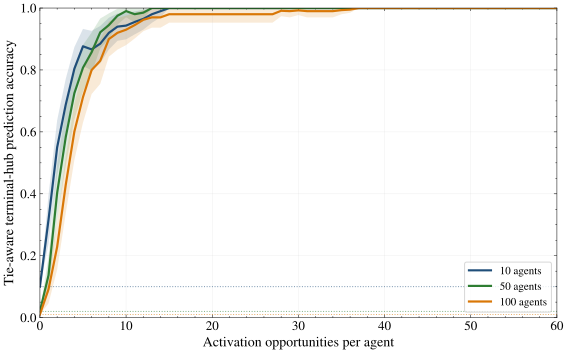

In [7]:
def draw_bayesian_bootstrap_mean_curves(matrix, key):
    """Draw the population mean curve under a Bayesian bootstrap."""
    values = jnp.asarray(matrix.to_numpy(dtype=np.float64))
    weights = dist.Dirichlet(jnp.ones(values.shape[0])).sample(
        key, sample_shape=(BAYESIAN_BOOTSTRAP_DRAWS,)
    )
    return np.asarray(weights @ values)


def posterior_interval(draws):
    return np.asarray(hpdi(jnp.asarray(draws), prob=CREDIBLE_MASS))


group_sizes = sorted(accuracy_matrices)
bootstrap_keys = random.split(
    random.key(BAYESIAN_BOOTSTRAP_SEED), len(group_sizes)
)
posterior_mean_curves = {
    n_agents: draw_bayesian_bootstrap_mean_curves(
        accuracy_matrices[n_agents], bootstrap_keys[group_index]
    )
    for group_index, n_agents in enumerate(group_sizes)
}

colors = {10: "#1f4e79", 50: "#2e7d32", 100: "#d97706"}
figure, axis = plt.subplots(figsize=(8.2, 5.2))
for n_agents in group_sizes:
    times = accuracy_matrices[n_agents].columns.to_numpy(dtype=np.float64)
    curve_draws = posterior_mean_curves[n_agents]
    lower, upper = posterior_interval(curve_draws)
    color = colors[n_agents]
    axis.fill_between(times, lower, upper, color=color, alpha=0.16, linewidth=0)
    axis.plot(
        times,
        curve_draws.mean(axis=0),
        color=color,
        linewidth=2.2,
        label=f"{n_agents} agents",
    )
    axis.axhline(1.0 / n_agents, color=color, linestyle=":", linewidth=1.0, alpha=0.6)

axis.set(
    xlim=(0.0, 60.0),
    ylim=(0.0, 1.0),
    xlabel="Activation opportunities per agent",
    ylabel="Tie-aware terminal-hub prediction accuracy",
)
axis.legend(loc="lower right", frameon=True)
axis.grid(alpha=0.2)
figure.tight_layout()
figure.savefig(FIGURE_PATH, format="pdf", dpi=300, bbox_inches="tight")
print(f"Saved figure: {FIGURE_PATH}")
plt.show()

## Bayesian ordering of the curves

The parameter vector is the independent sampling unit. Following [Rubin's Bayesian bootstrap](https://doi.org/10.1214/aos/1176345338), independent $\operatorname{Dirichlet}(1, \ldots, 1)$ posterior weights are placed on the observed trajectories in each group. This gives a posterior over the 61-dimensional mean curve, an application of Bayesian-bootstrap inference for [multidimensional mean functionals](https://doi.org/10.1214/aos/1024691463). The same draws determine the normalized area under each mean curve, its average predictability over the horizon.

For each pair $(a,b)$, let $\Delta_{a,b}=\operatorname{AUC}_a-\operatorname{AUC}_b$. The plots explicitly encode $H_+:\Delta_{a,b}>0$ and $H_-:\Delta_{a,b}\leq0$; each shaded area is its posterior probability. Because the Bayesian-bootstrap posterior is continuous, $P(\Delta_{a,b}=0\mid\text{data})=0$. A point-null probability would require a spike prior, while practical equivalence would require a ROPE; neither is introduced here. Results also report 95% highest-posterior-density intervals, all six complete AUC-order hypotheses, and joint pointwise-dominance probabilities.

,n_agents,posterior_mean_auc,posterior_median_auc,credible_interval_low,credible_interval_high
0,10,0.9538,0.9541,0.9444,0.9622
1,50,0.9470,0.9471,0.9398,0.9544
2,100,0.9243,0.9252,0.9087,0.9383


,comparison,directional_hypothesis,posterior_mean_difference,difference_percentage_points,credible_interval_low,credible_interval_high,posterior_probability_h_plus,posterior_probability_h_minus,probability_left_dominates_curve,probability_right_dominates_curve
0,10 - 50,H+: 10 > 50,0.0068,0.68,-0.0050,0.0182,0.876,0.124,0.000,0.000
1,10 - 100,H+: 10 > 100,0.0296,2.96,0.0126,0.0481,1.000,0.000,0.405,0.000
2,50 - 100,H+: 50 > 100,0.0227,2.27,0.0062,0.0401,0.999,0.001,0.651,0.000


,complete_order_hypothesis,posterior_probability
0,10 > 50 > 100,0.8750
1,50 > 10 > 100,0.1242
2,10 > 100 > 50,0.0008
3,50 > 100 > 10,0.0001
4,100 > 10 > 50,0.0001
5,100 > 50 > 10,0.0000


Saved posterior hypothesis figure: /home/hdahmou/Projects/Network_creation/artifacts/figures/run-20260809T034029/terminal_hub_predictability_bayesian_hypotheses.pdf


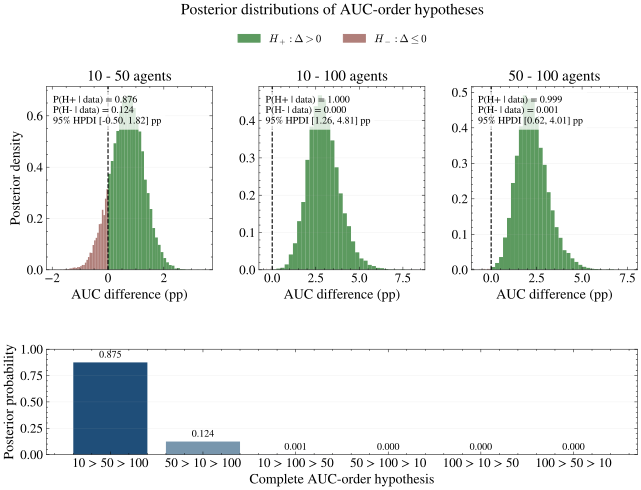

Most probable complete AUC ordering: 10 > 50 > 100 (posterior probability 0.875).
P(10 > 100 and 50 > 100 | data) = 0.999.


In [8]:
def normalized_curve_area(curve_draws, times):
    duration = times[-1] - times[0]
    return np.trapezoid(curve_draws, times, axis=1) / duration


times = accuracy_matrices[group_sizes[0]].columns.to_numpy(dtype=np.float64)
posterior_auc_by_size = {
    n_agents: normalized_curve_area(posterior_mean_curves[n_agents], times)
    for n_agents in group_sizes
}

auc_summary_rows = []
for n_agents, auc_draws in posterior_auc_by_size.items():
    lower, upper = posterior_interval(auc_draws)
    auc_summary_rows.append({
        "n_agents": n_agents,
        "posterior_mean_auc": auc_draws.mean(),
        "posterior_median_auc": np.median(auc_draws),
        "credible_interval_low": lower,
        "credible_interval_high": upper,
    })
auc_summary = pd.DataFrame(auc_summary_rows)
display(auc_summary.style.format({
    "posterior_mean_auc": "{:.4f}",
    "posterior_median_auc": "{:.4f}",
    "credible_interval_low": "{:.4f}",
    "credible_interval_high": "{:.4f}",
}))

pairs = [(10, 50), (10, 100), (50, 100)]
pairwise_rows = []
posterior_difference_by_pair = {}
for left_size, right_size in pairs:
    difference_draws = (
        posterior_auc_by_size[left_size] - posterior_auc_by_size[right_size]
    )
    posterior_difference_by_pair[(left_size, right_size)] = difference_draws
    lower, upper = posterior_interval(difference_draws)
    left_curve_draws = posterior_mean_curves[left_size]
    right_curve_draws = posterior_mean_curves[right_size]
    pairwise_rows.append({
        "comparison": f"{left_size} - {right_size}",
        "directional_hypothesis": f"H+: {left_size} > {right_size}",
        "posterior_mean_difference": difference_draws.mean(),
        "difference_percentage_points": 100.0 * difference_draws.mean(),
        "credible_interval_low": lower,
        "credible_interval_high": upper,
        "posterior_probability_h_plus": np.mean(difference_draws > 0.0),
        "posterior_probability_h_minus": np.mean(difference_draws <= 0.0),
        "probability_left_dominates_curve": np.mean(np.all(
            left_curve_draws >= right_curve_draws - 1e-12, axis=1
        )),
        "probability_right_dominates_curve": np.mean(np.all(
            right_curve_draws >= left_curve_draws - 1e-12, axis=1
        )),
    })
pairwise = pd.DataFrame(pairwise_rows)
np.testing.assert_allclose(
    pairwise["posterior_probability_h_plus"]
    + pairwise["posterior_probability_h_minus"],
    1.0,
)
display(pairwise.style.format({
    "posterior_mean_difference": "{:.4f}",
    "difference_percentage_points": "{:.2f}",
    "credible_interval_low": "{:.4f}",
    "credible_interval_high": "{:.4f}",
    "posterior_probability_h_plus": "{:.3f}",
    "posterior_probability_h_minus": "{:.3f}",
    "probability_left_dominates_curve": "{:.3f}",
    "probability_right_dominates_curve": "{:.3f}",
}))

ordering_rows = []
for ordering in permutations(group_sizes):
    ordered_auc_draws = np.column_stack([
        posterior_auc_by_size[n_agents] for n_agents in ordering
    ])
    ordering_rows.append({
        "complete_order_hypothesis": " > ".join(map(str, ordering)),
        "posterior_probability": np.mean(np.all(
            ordered_auc_draws[:, :-1] > ordered_auc_draws[:, 1:], axis=1
        )),
    })
ordering_probabilities = (
    pd.DataFrame(ordering_rows)
    .sort_values("posterior_probability", ascending=False)
    .reset_index(drop=True)
)
np.testing.assert_allclose(ordering_probabilities["posterior_probability"].sum(), 1.0)
display(ordering_probabilities.style.format({"posterior_probability": "{:.4f}"}))

positive_color = "#2e7d32"
negative_color = "#9a5b55"
hypothesis_figure = plt.figure(figsize=(10.6, 7.2))
grid = hypothesis_figure.add_gridspec(
    2, 3, height_ratios=(2.0, 1.15), hspace=0.55, wspace=0.28
)
for pair_index, (left_size, right_size) in enumerate(pairs):
    axis = hypothesis_figure.add_subplot(grid[0, pair_index])
    difference_draws = 100.0 * posterior_difference_by_pair[(left_size, right_size)]
    minimum = min(0.0, difference_draws.min())
    maximum = max(0.0, difference_draws.max())
    negative_edges = (
        np.linspace(minimum, 0.0, 36) if minimum < 0.0 else np.array([0.0])
    )
    positive_edges = (
        np.linspace(0.0, maximum, 36) if maximum > 0.0 else np.array([0.0])
    )
    bin_edges = np.unique(np.concatenate((negative_edges, positive_edges)))
    density, bin_edges = np.histogram(difference_draws, bins=bin_edges, density=True)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    axis.bar(
        bin_centers,
        density,
        width=np.diff(bin_edges),
        color=np.where(bin_centers > 0.0, positive_color, negative_color),
        alpha=0.78,
        linewidth=0,
    )
    probability_h_plus = np.mean(difference_draws > 0.0)
    interval_low, interval_high = posterior_interval(difference_draws)
    axis.axvline(0.0, color="black", linestyle="--", linewidth=1.1)
    axis.text(
        0.04,
        0.95,
        f"P(H+ | data) = {probability_h_plus:.3f}\n"
        f"P(H- | data) = {1.0 - probability_h_plus:.3f}\n"
        f"95% HPDI [{interval_low:.2f}, {interval_high:.2f}] pp",
        transform=axis.transAxes,
        va="top",
        fontsize=10,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.78},
    )
    axis.set(
        title=f"{left_size} - {right_size} agents",
        xlabel="AUC difference (pp)",
        ylabel="Posterior density" if pair_index == 0 else None,
    )
    axis.grid(axis="y", alpha=0.18)

order_axis = hypothesis_figure.add_subplot(grid[1, :])
order_bars = order_axis.bar(
    ordering_probabilities["complete_order_hypothesis"],
    ordering_probabilities["posterior_probability"],
    color=["#1f4e79", "#7896ad", "#b6c4cf", "#b6c4cf", "#b6c4cf", "#b6c4cf"],
)
for bar, probability in zip(
    order_bars, ordering_probabilities["posterior_probability"], strict=True
):
    order_axis.text(
        bar.get_x() + bar.get_width() / 2.0,
        max(probability + 0.025, 0.025),
        f"{probability:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
    )
order_axis.set(
    ylim=(0.0, 1.0),
    xlabel="Complete AUC-order hypothesis",
    ylabel="Posterior probability",
)
order_axis.grid(axis="y", alpha=0.18)
hypothesis_figure.suptitle("Posterior distributions of AUC-order hypotheses")
hypothesis_figure.legend(
    handles=[
        Patch(color=positive_color, alpha=0.78, label=r"$H_+: \Delta > 0$"),
        Patch(color=negative_color, alpha=0.78, label=r"$H_-: \Delta \leq 0$"),
    ],
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 0.94),
)
hypothesis_figure.subplots_adjust(top=0.82, bottom=0.11)
hypothesis_figure.savefig(
    HYPOTHESIS_FIGURE_PATH, format="pdf", dpi=300, bbox_inches="tight"
)
print(f"Saved posterior hypothesis figure: {HYPOTHESIS_FIGURE_PATH}")
plt.show()

partial_order_probability = np.mean(
    (posterior_auc_by_size[10] > posterior_auc_by_size[100])
    & (posterior_auc_by_size[50] > posterior_auc_by_size[100])
)
most_likely_order = ordering_probabilities.iloc[0]
print(
    "Most probable complete AUC ordering: "
    f"{most_likely_order['complete_order_hypothesis']} "
    f"(posterior probability {most_likely_order['posterior_probability']:.3f})."
)
print(
    "P(10 > 100 and 50 > 100 | data) = "
    f"{partial_order_probability:.3f}."
)